In [1]:
%pip install h5py

   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.2 MB ? eta -:--:--
   ----------------------------- ---------- 2.4/3.2 MB 9.0 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 8.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [82]:
import h5py
import numpy as np 
import matplotlib.pyplot as plt 
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2

In [ ]:
# i used singlecoil_val , because train is too big to extract , singlecoil_test doesn't contain the references , all the notebook is jus about understnding the dataset and tryin to construct a dataloader to feed data to our CNN network archtecture ; 
f = h5py.File("./singlecoil_val/file1000000.h5","r")
print(list(f.keys()))
dset = f['kspace']
print(dset.shape)
print(dset.dtype)
print(dset.name)
print(f.name)


['ismrmrd_header', 'kspace', 'reconstruction_esc', 'reconstruction_rss']
(35, 640, 368)
complex64
/kspace
/


(35, 320, 320)
float32


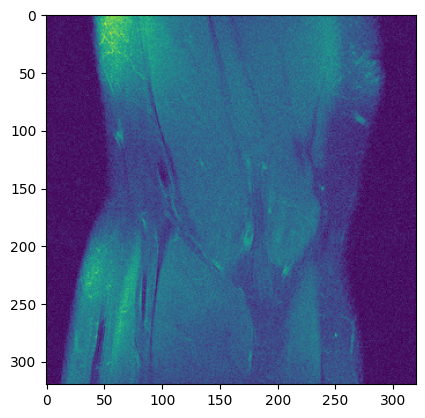

In [ ]:
# displaying  the last slice of the inverse FFT reconstruction applied to a spatial cropped single_coil k-space 
dset1 =f['reconstruction_esc']
print(dset1.shape)
print(dset1.dtype)
ref =dset1[34]
plt.imshow(ref)

(35, 320, 320)


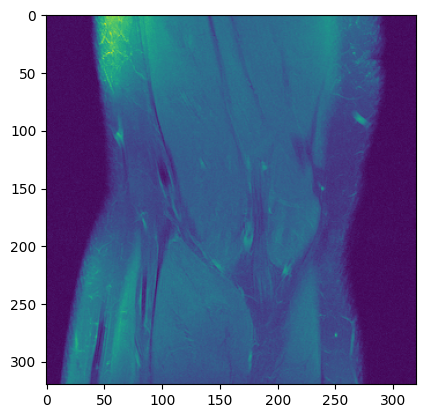

In [72]:
# displaying  the last slice of our grounded truth  references 
dset2 = f['reconstruction_rss']
print(dset2.shape)
ref1=dset2[34]
plt.imshow(ref1)
plt.show()

(35, 640, 368) (368,)
complex64
min/max  of abs : 0.0 1.8536215e-05
[[0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]
 ...
 [0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j ... 0.+0.j 0.+0.j 0.+0.j]]


2

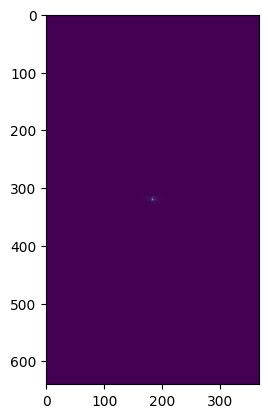

In [ ]:
# inspecting the k-space dataset of our first File object 
dset_k = f['kspace'] 
print(dset_k.shape , ref_k[0].shape ) 
print(dset_k.dtype)
# the abs in complexe numbers is like the modulo not just absolute value , we use it here cause the values are too small and (print) only prints 0 but it's not like that , there's values captured by the RMI , but very small 

print("min/max  of abs :", np.abs(ref_k[0]).min() , np.abs(ref_k[0]).max())
ref_k = dset_k[34] #middle slice 
mag = np.abs(ref_k) #magnitude , real : we converted the complxe into real numbers by computing their magnitude 
plt.imshow(np.log1p(mag), )  # we applied log1p to compress the huge dynamic range so that we can get an image with a white point in the middle witout losing it cause of the massive darkness in the image 

print(ref_k )
ref_k.ndim


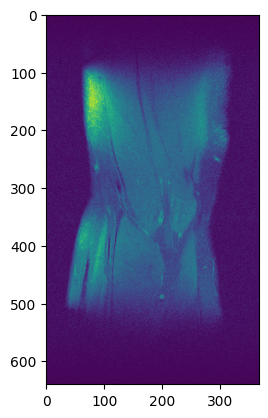

In [81]:
import numpy as np 
a = np.abs(np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(ref_k))))

plt.imshow(a)



In [ ]:
import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self,h5_paths, mask, crop_indices ):
        self.h5_paths = h5_paths 
        self.index =  []
        for path in h5_paths:
            with h5py.File(path) as f:
                kspace = f['kspace']
                num_slices = kspace.shape[0]
                for s in range(num_slices):
                    self.index.append((path,s))
        self.mask = torch.from_numpy(mask) 
        self.crop_indices = crop_indices

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        path , slice_idx = self.index[idx]
        with h5py.File(path, 'r') as f :
            kspace = f['kspace'][slice_idx]
            target = f['reconstruction_rss'][slice_idx]
        kspace_t = torch.from_numpy(kspace)
        target_t = torch.from_numpy(target).float()
        mask_t = self.mask
        return kspace_t ,  mask_t , target_t 